# Ejemplos completos de la clase 2
El mismo programa está incluido en el anexo del Word Tema. Todos los datos se generan aquí o se cargan desde los conjuntos incorporados en scikit-learn. Las cuatro figuras se guardan en Figuras. Fuente del código: elaboración propia para el curso.

Mayor similitud entre textos distintos 0.6639942038552976


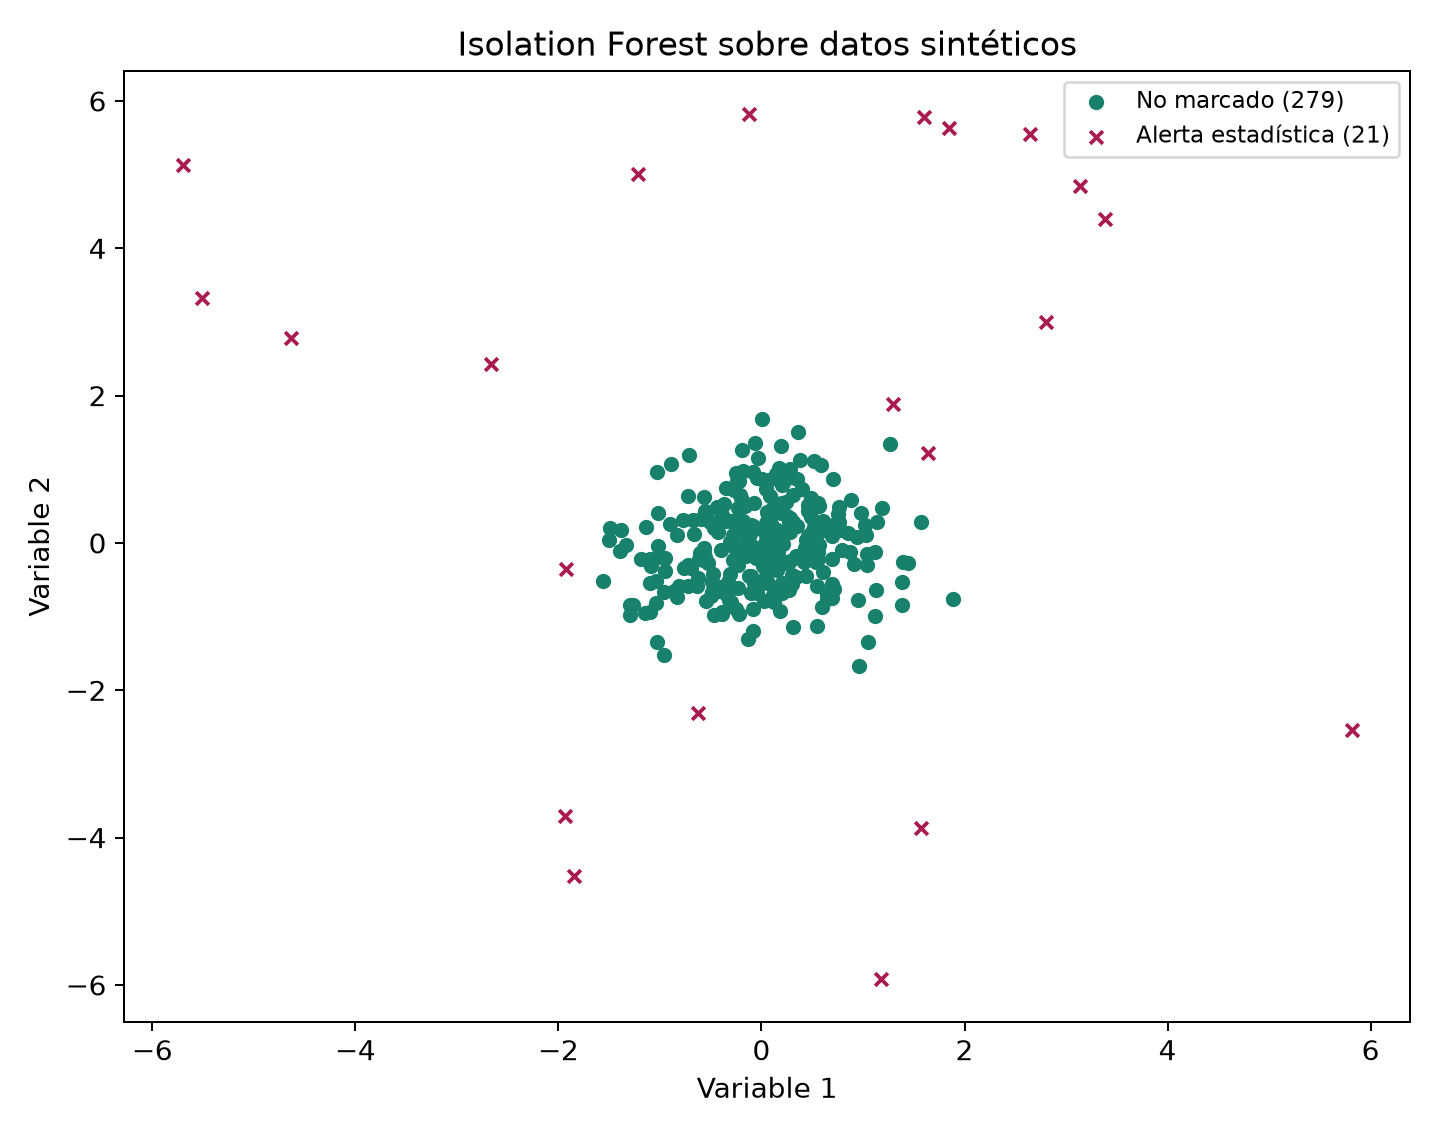

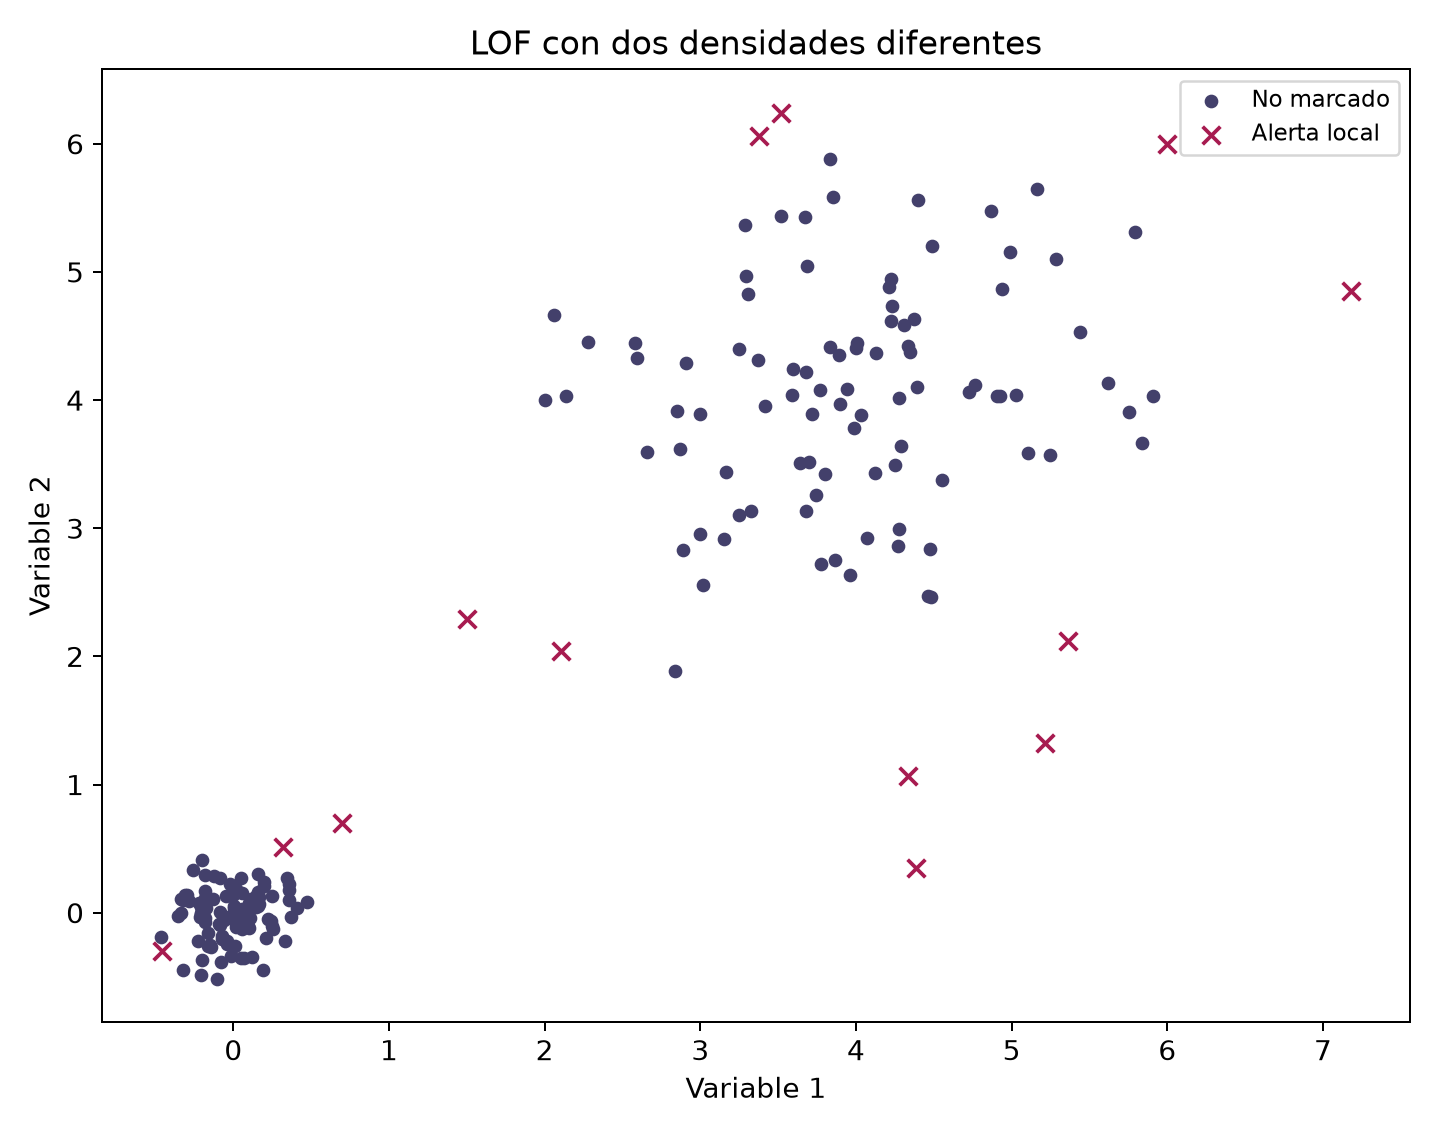

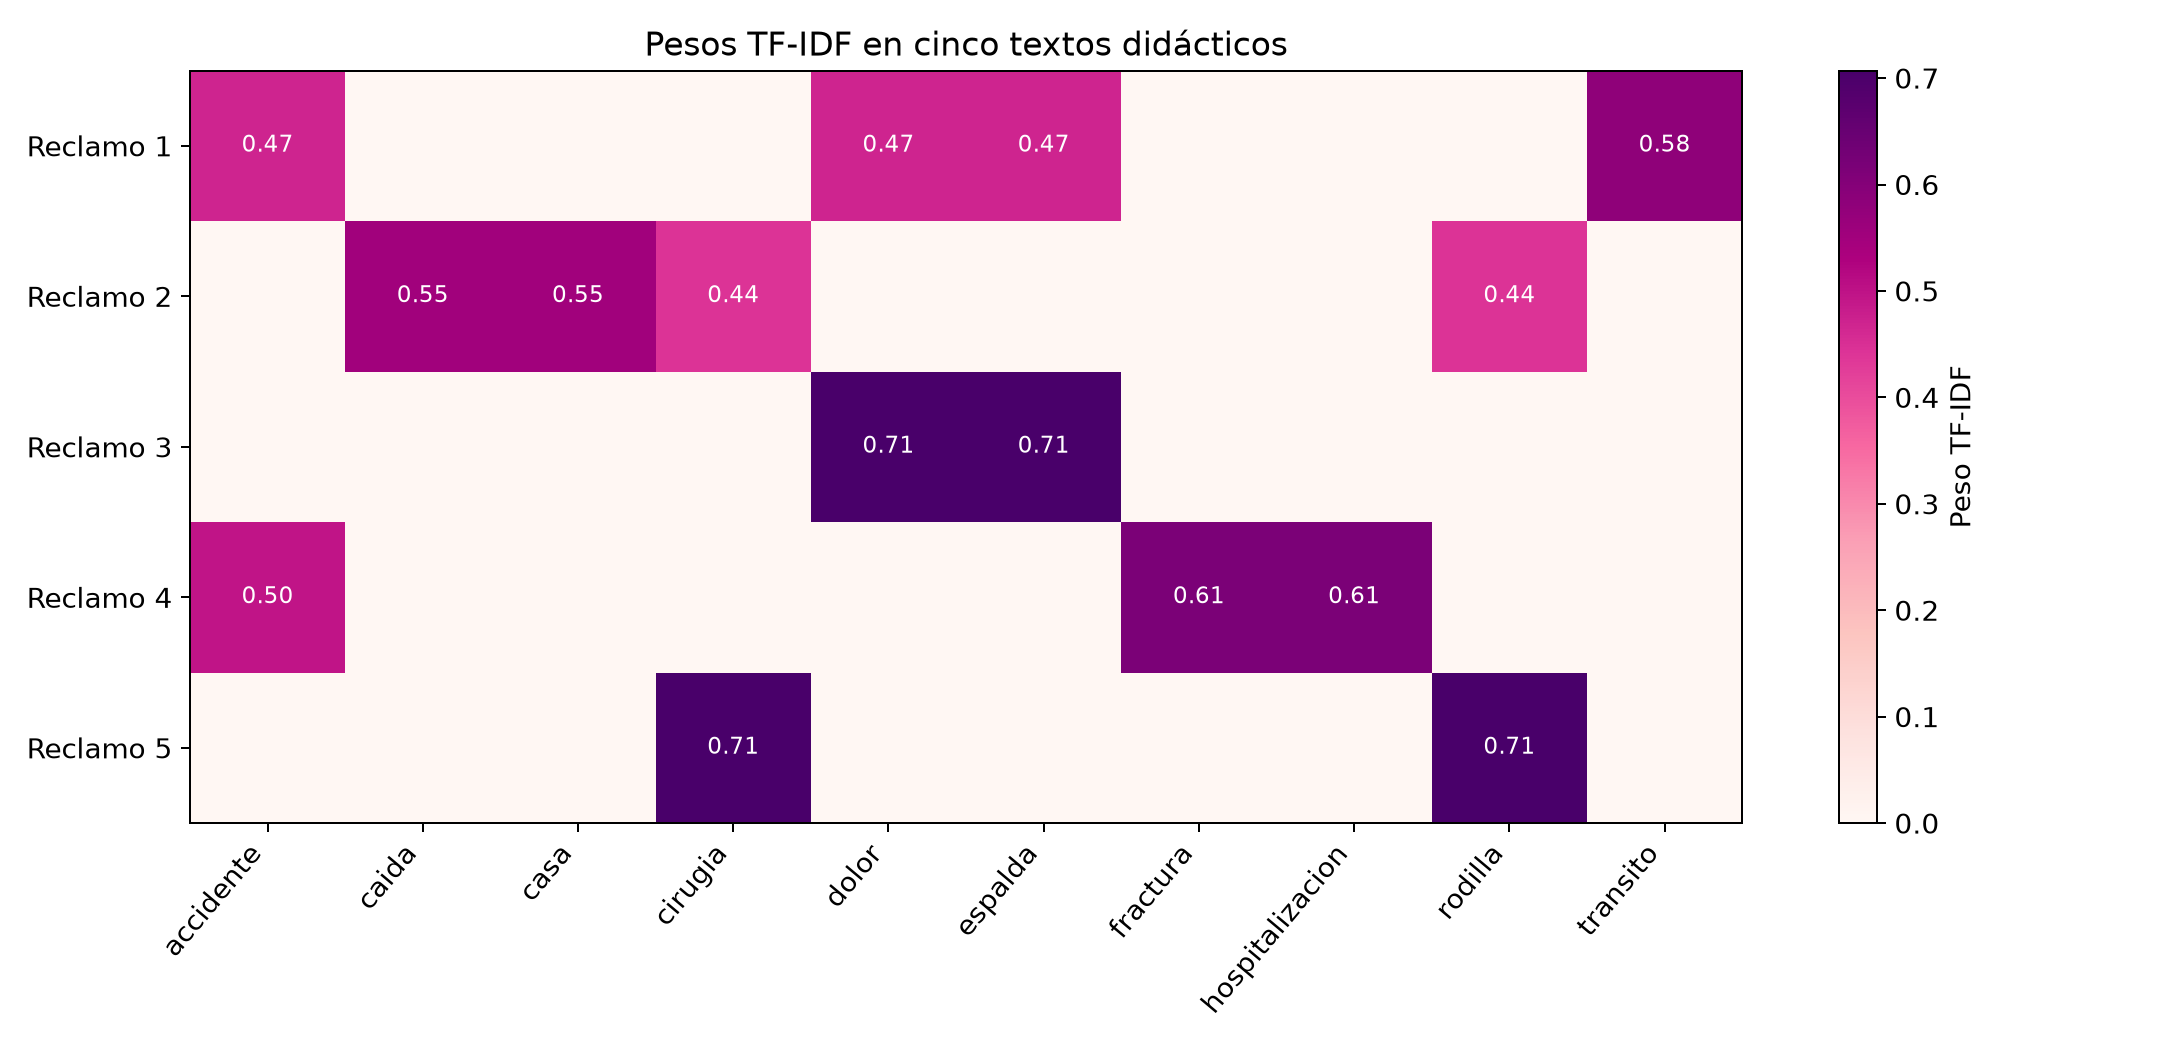

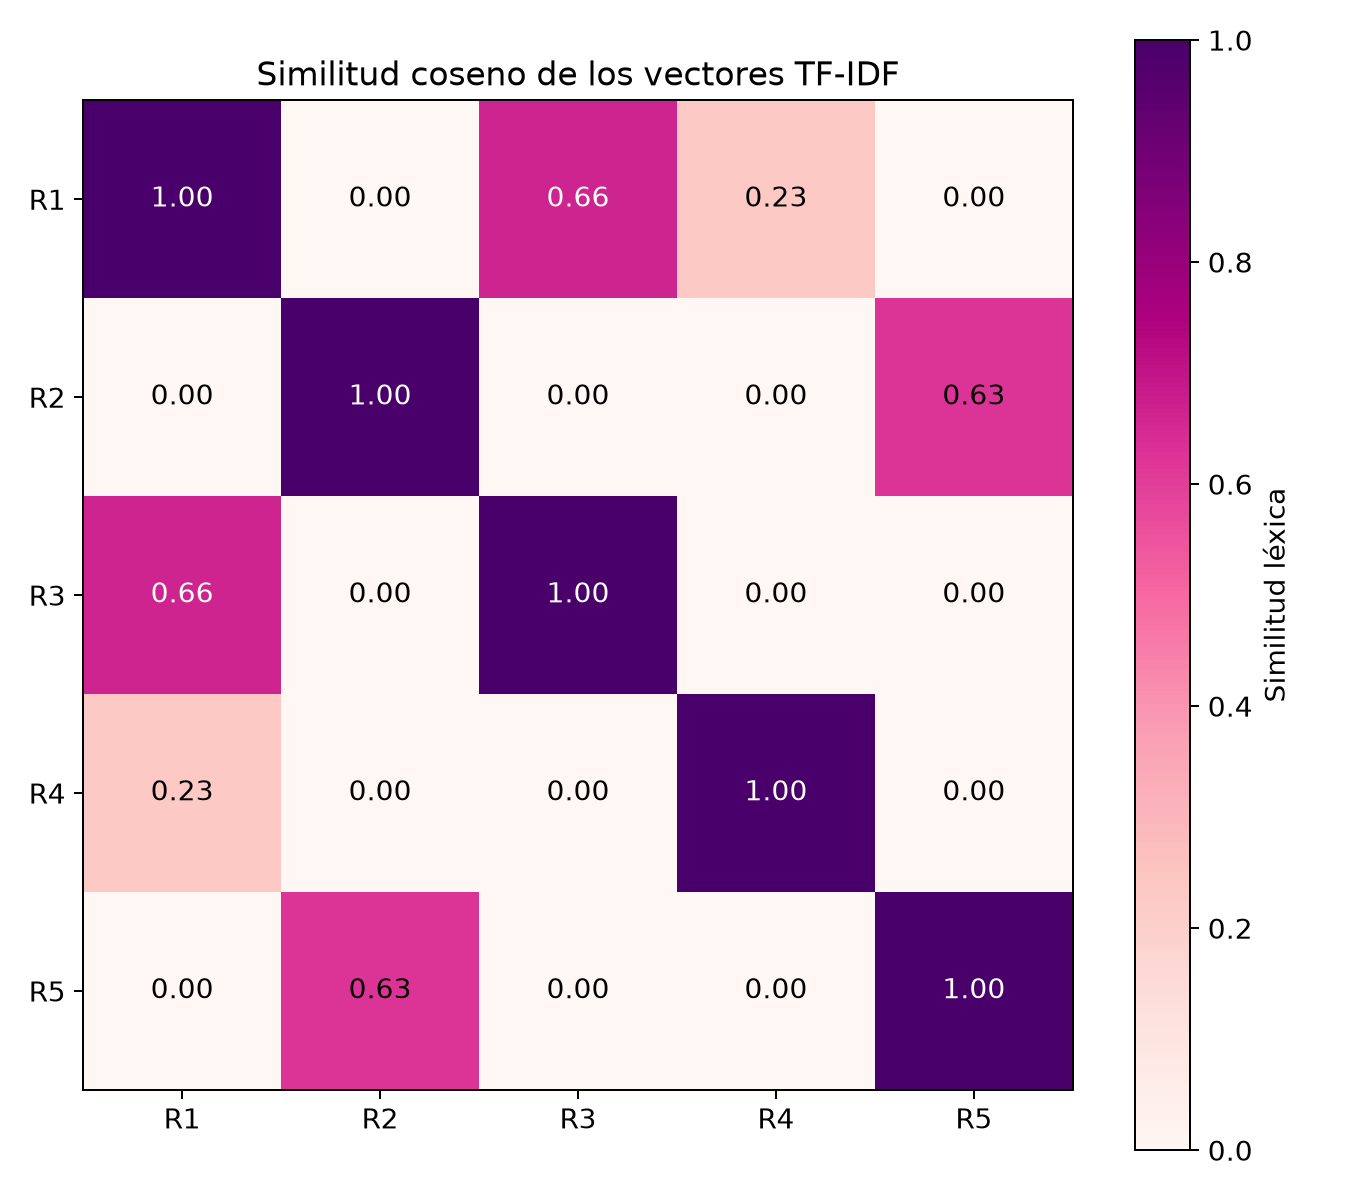

In [1]:
from pathlib import Path
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs, load_wine, load_digits
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
BASE = Path.cwd()
OUT = BASE / "Figuras"
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.titlesize": 13, "figure.dpi": 160})
colores = ["#a71b50", "#18816c", "#43406b", "#ed6589"]
def save(fig, n):
    fig.tight_layout()
    fig.savefig(OUT / f"figura_{n}.png", dpi=180)
    plt.close(fig)
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
rng = np.random.default_rng(42)
X = np.vstack([rng.normal(0,.65,(280,2)),rng.uniform(-6,6,(20,2))])
modelo=IsolationForest(contamination=.07,random_state=42).fit(X)
pred=modelo.predict(X)
fig, ax=plt.subplots(figsize=(8,6.3))
for mask,color,marker,label in [(pred==1,colores[1],"o","No marcado"),(pred==-1,colores[0],"x","Alerta estadística")]:
    ax.scatter(*X[mask].T,c=color,marker=marker,s=26,label=f"{label} ({mask.sum()})")
ax.set(xlabel="Variable 1",ylabel="Variable 2",title="Isolation Forest sobre datos sintéticos")
ax.legend(fontsize=9);save(fig,1)
X=np.vstack([rng.normal(0,.2,(100,2)),rng.normal(4,1,(100,2)),[[.7,.7],[2,4],[6,6]]])
lof=LocalOutlierFactor(n_neighbors=20,contamination=.06)
pred=lof.fit_predict(X)
fig,ax=plt.subplots(figsize=(8,6.3))
ax.scatter(*X[pred==1].T,color=colores[2],s=20,label="No marcado")
ax.scatter(*X[pred==-1].T,color=colores[0],marker="x",s=50,label="Alerta local")
ax.set(xlabel="Variable 1",ylabel="Variable 2",title="LOF con dos densidades diferentes")
ax.legend(fontsize=9);save(fig,2)
reclamos=["dolor espalda accidente transito", "cirugia rodilla caida casa", "dolor espalda", "accidente fractura hospitalizacion", "cirugia rodilla"]
v=TfidfVectorizer()
T=v.fit_transform(reclamos)
fig,ax=plt.subplots(figsize=(12,5.8));im=ax.imshow(T.toarray(),cmap="RdPu",aspect="auto",vmin=0)
ax.set_xticks(range(len(v.get_feature_names_out())),v.get_feature_names_out(),rotation=50,ha="right")
ax.set_yticks(range(5),[f"Reclamo {i+1}" for i in range(5)])
for i in range(5):
    for j in range(T.shape[1]):
        if T[i,j]>0:ax.text(j,i,f"{T[i,j]:.2f}",ha="center",va="center",color="white",fontsize=9)
ax.set_title("Pesos TF-IDF en cinco textos didácticos");fig.colorbar(im,ax=ax,label="Peso TF-IDF");save(fig,3)
S=cosine_similarity(T)
fig,ax=plt.subplots(figsize=(7.5,6.65));im=ax.imshow(S,vmin=0,vmax=1,cmap="RdPu")
for i in range(5):
    for j in range(5):ax.text(j,i,f"{S[i,j]:.2f}",ha="center",va="center",color="white" if S[i,j]>.65 else "black")
ax.set_xticks(range(5),[f"R{i+1}" for i in range(5)]);ax.set_yticks(range(5),[f"R{i+1}" for i in range(5)])
ax.set_title("Similitud coseno de los vectores TF-IDF")
fig.colorbar(im,ax=ax,label="Similitud léxica");save(fig,4)
print("Mayor similitud entre textos distintos", float((S-np.eye(5)).max()))
